# HW4 - Design of Experiments

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import doe

import statsmodels.api as sm

### Define the problem

The goal of this problem is to analyze how bit size (A) and cutting speed (B) affect vibration during circuit board cutting.

In [2]:
# Import data
df = pd.read_csv("circuit-board.csv")
_, n_replicates = df.shape
responses = df.to_numpy()

A: 16.637500000000003
B: 7.537500000000005
AB: 8.7125


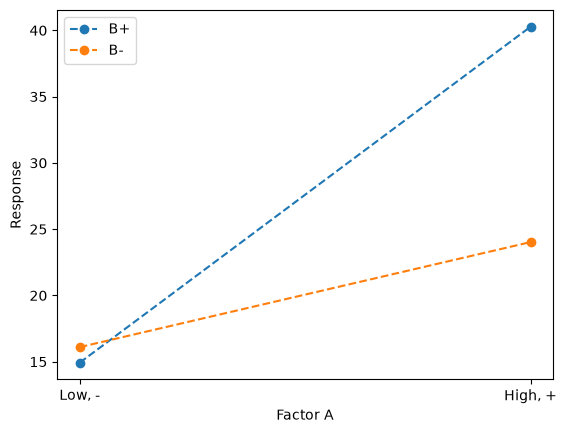

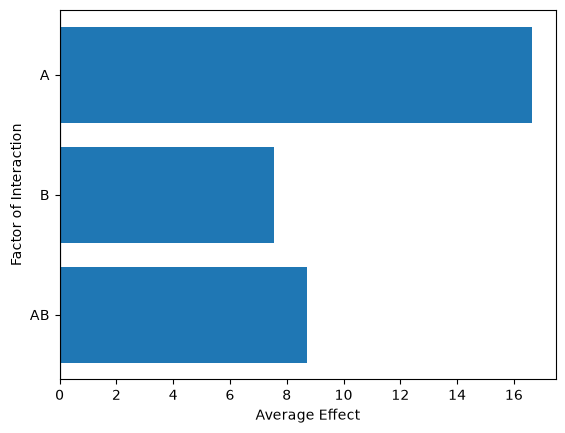

In [3]:
# Analyze and discuss the main & interaction effects

effect_result = doe.effects(responses, n_replicates)

print("A:", effect_result[0])
print("B:", effect_result[1])
print("AB:", effect_result[2])

doe.plot_effects(responses, n_replicates)
plt.show()

doe.plot_tornado(responses, n_replicates)
plt.show()


The main effects of bit size (A) is 16.6375 and cutting speed (B) is 7.5375. These values represent the average differences in vibration when each factor changes from its low level to high level. There is a positive interaction between bit size and cutting speed, as shown by the line plot that has non-parallel lines. Increasing cutting speed slightly decreases vibration at A-, but substantially increases it at A+; thus the effect of cutting speed on vibration depends on bit size, and vice versa.

As a result, since the effect of A is the biggest, bit size has the greatest influence on average vibration among the factors. Also, the positive interaction effect indicates that the effect of bit size on vibration depends on cutting speed; increasing both A and B from their low levels to high levels produces a greater increase in vibration than would be expected from their individual main effects alone.

In [4]:
# ANOVA

y = responses.flatten()

A = np.repeat([-1, 1, -1, 1], n_replicates)
B = np.repeat([-1, -1, 1, 1], n_replicates)
AB = A * B

X = np.column_stack((np.ones(len(y)), A, B, AB))

results = sm.OLS(y, X).fit()

X_cols_name = ["(1)", "A", "B", "AB"]

print(results.summary(xname=X_cols_name))

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.948
Method:                 Least Squares   F-statistic:                     91.36
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           1.57e-08
Time:                        21:13:35   Log-Likelihood:                -34.705
No. Observations:                  16   AIC:                             77.41
Df Residuals:                      12   BIC:                             80.50
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
(1)           23.8313      0.611     38.991      0.0

In [5]:
# F-test
print("F-stat: ",results.fvalue)
print()
print("p-value: ", results.f_pvalue)

F-stat:  91.35832549060616

p-value:  1.5685949039903473e-08


In [6]:
# T-test
for name, coef, tval, pval in zip(X_cols_name, results.params, results.tvalues, results.pvalues):
    print(name, ": coef = ", coef, ", t-value = ", tval, ", p-value = ", pval)

(1) : coef =  23.83125000000001 , t-value =  38.99148066120994 , p-value =  5.220821788591207e-14
A : coef =  8.318750000000009 , t-value =  13.610716171012443 , p-value =  1.1746693237294825e-08
B : coef =  3.7687499999999967 , t-value =  6.166237303621706 , p-value =  4.826291781692741e-05
AB : coef =  4.356250000000003 , t-value =  7.127474959576013 , p-value =  1.2010783458951853e-05


### Analyze and discuss using ANOVA

The overall F-test evaluates whether the factors collectively have a statistically significant effect on vibration. The p-value is less than 0.05, indicating that the model is statistically significant.

The individual t-tests indicate that the main effects A and B, and the interaction AB are statistically significant at the 5% significance level, since all p-values are less than 0.05.

Among these test results, factor A has the largest absolute t-statistic, indicating that bit size has the strongest effect on vibration. This is consistent with the previous main effect analysis, where A shows the largest effect. The AB interaction also indicates that the effect of one factor on vibration depends on the level of the other factor.

### Recommendation

Based on the test results, I recommend A- and B+, which is using a bit size of 1/16 in and a cutting speed of 90 rpm. This combination produces the lowest mean vibration of (15.9 + 14.5 + 15.1 + 14.2)/4 = 14.925 among the four conditions.

Although the main effect of cutting speed is positive, increasing speed from 40 to 90 rpm slightly decreases vibration when bit size is small. This behavior is explained by the interaction between A and B, and this is shown in the line plot of effects.

Therefore, considering both the main and interaction effects, the set of smaller bit size and higher cutting speed is recommended to minimize the vibration within the tested conditions.